In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image

#original_dir = pathlib.Path("./data")
base_dir = pathlib.Path("./datasets/data_sorted")

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
categories = ["bowl", "glass", "mug", "plate"]
splits = ["train", "validation", "test"]
image_extensions = ('.jpg', '.jpeg')

def count_dataset_images():
    for split in splits:
        print(f"\nsplit: {split}")
        total = 0

        for category in categories:
            folder = os.path.join("./datasets/data_sorted", split, category)

            image_count = sum(
                1 for filename in os.listdir(folder)
                if filename.lower().endswith(image_extensions)
            )

            total += image_count

            print(f"  {category}: {image_count} images")

        print(f"  Total: {total} images")



count_dataset_images()


split: train
  bowl: 56 images
  glass: 59 images
  mug: 62 images
  plate: 55 images
  Total: 232 images

split: validation
  bowl: 11 images
  glass: 13 images
  mug: 14 images
  plate: 11 images
  Total: 49 images

split: test
  bowl: 13 images
  glass: 14 images
  mug: 14 images
  plate: 12 images
  Total: 53 images


In [3]:
train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)

Found 232 files belonging to 4 classes.
Found 49 files belonging to 4 classes.
Found 53 files belonging to 4 classes.


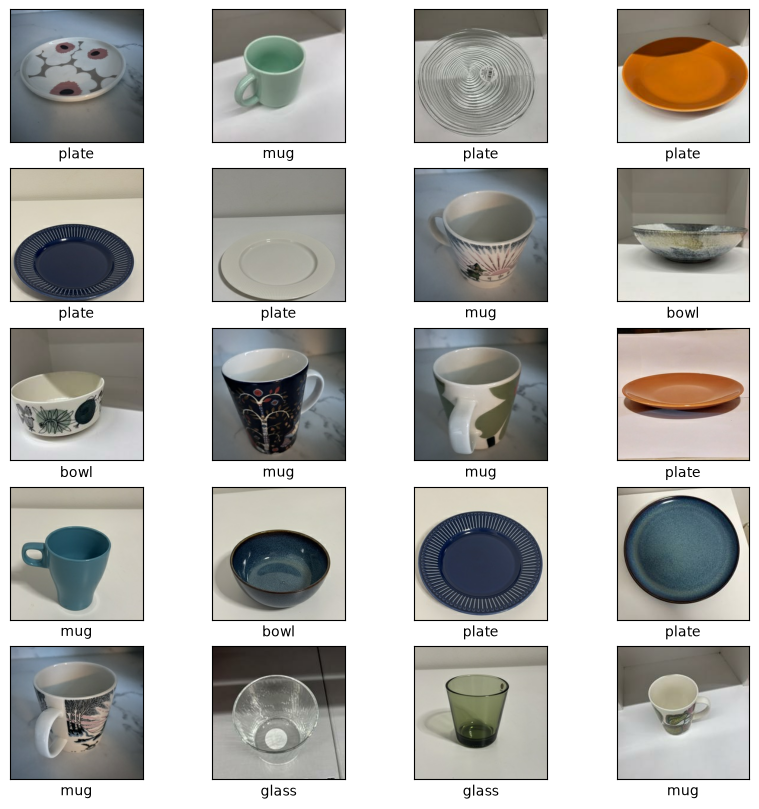

In [4]:
import matplotlib.pyplot as plt

# Haetaan yksi batch kuvista ja labeleista
plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

In [5]:
from keras import Sequential
from keras import layers

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0/255)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation='softmax') (x)
model = keras.Model(inputs=inputs, outputs=outputs)


model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       102,404 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,080,900 (4.12 MB)

 Trainable params: 1,080,900 (4.12 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
for data_batch, labels_batch in train_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break

data batch shape: (32, 224, 224, 3)
labels batch shape: (32,)


In [7]:
callbacks = [keras.callbacks.ModelCheckpoint(
    filepath = "convnet_from_scratch_with_augmentation.keras",
    save_best_only = True,
    monitor = "val_loss")]

In [8]:
history = model.fit(
    train_dataset, 
    validation_data=validation_dataset,    
    epochs=20, 
    verbose=1,
    callbacks = callbacks)

Epoch 1/20


C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 912ms/step - accuracy: 0.2069 - loss: 1.3989 - val_accuracy: 0.2857 - val_loss: 1.3823
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 888ms/step - accuracy: 0.2629 - loss: 1.3857 - val_accuracy: 0.2857 - val_loss: 1.3768
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.2716 - loss: 1.3867 - val_accuracy: 0.3061 - val_loss: 1.3652
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3233 - loss: 1.3388 - val_accuracy: 0.4082 - val_loss: 1.3020
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.3836 - loss: 1.2667 - val_accuracy: 0.6122 - val_loss: 1.3900
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.4612 - loss: 1.2156 - val_accuracy: 0.4082 - val_loss: 1.2650
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.4526 - loss: 1.2171 - val_accuracy: 0.4490 - val_loss: 1.5723
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.4698 - loss: 1.1589 - val_accuracy: 0.5510 - val_loss: 1.3205
Epoch 9/20
8/8 ━━━━

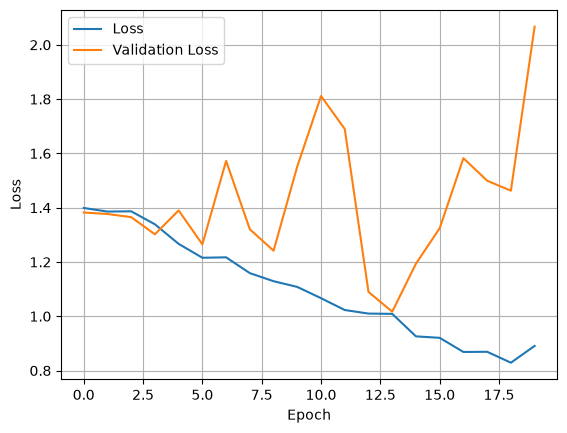

In [9]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

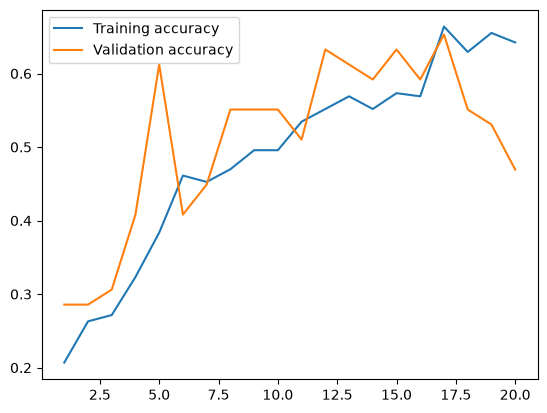

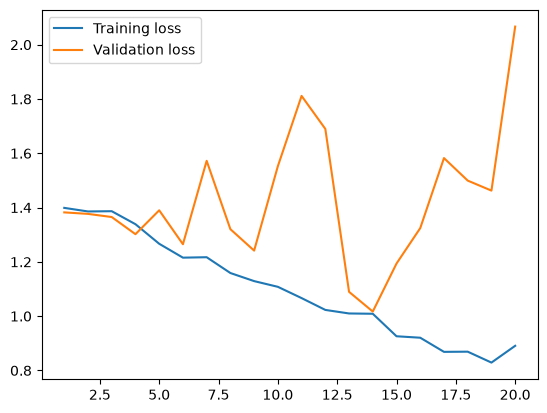

In [10]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = list(range(1, len(accuracy)+1))
plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.legend()
plt.show()

In [11]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 441ms/step - accuracy: 0.4906 - loss: 1.3380
Test accuracy: 0.491


In [12]:
train_full = train_dataset.concatenate(validation_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 698ms/step


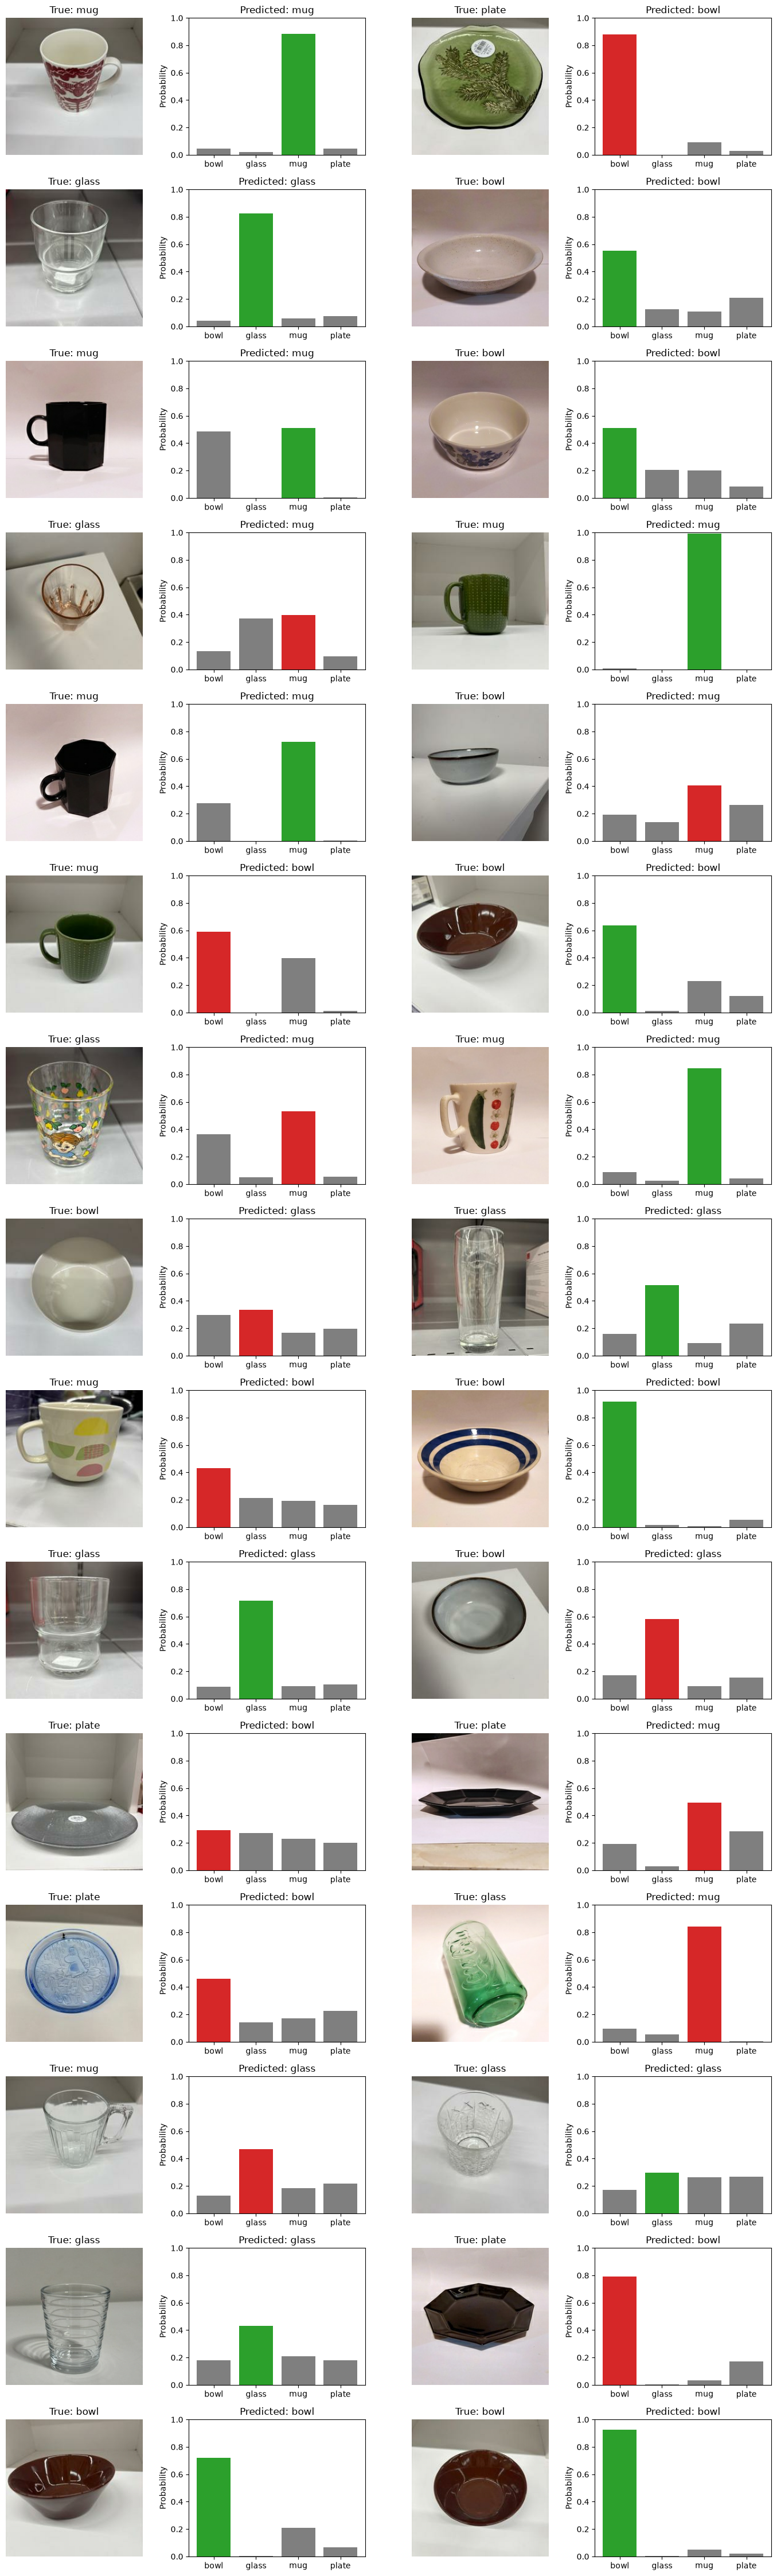

In [16]:
x, y = next(iter(test_dataset)) 
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()